In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys
for pkg in ['tensorflow','numpy','pandas','scipy',
            'matplotlib','seaborn','scikit-learn','tqdm']:
    imp = 'sklearn' if pkg=='scikit-learn' else pkg
    try: __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',
                               '-q',pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel('ERROR')

strategy = tf.distribute.MirroredStrategy()
N_GPUS   = strategy.num_replicas_in_sync

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
                     'font.size':11,'savefig.bbox':'tight'})
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f'TF {tf.__version__}  |  GPUs (MirroredStrategy): {N_GPUS}')
print('Imports complete.')

TF 2.20.0  |  GPUs (MirroredStrategy): 2
Imports complete.


I0000 00:00:1786732712.192163      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786732712.195109      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Set P5A_DIR to the dataset extracted from part5a_yamnet.zip

P5A_DIR  = '/kaggle/input/datasets/imemon1044/part5a-yamnet1'

EMB_PATH = os.path.join(P5A_DIR, 'yamnet_emb_all.npy')
MASK_PATH= os.path.join(P5A_DIR, 'yamnet_emb_mask.npy')
SEG_CSV  = os.path.join(P5A_DIR, 'segments.csv')

WORK_DIR = '/kaggle/working'
OUT_DIR  = os.path.join(WORK_DIR, 'part5a_v2')
FIG_DIR  = os.path.join(OUT_DIR,  'figures')
MDL_DIR  = os.path.join(OUT_DIR,  'models')
LOG_DIR  = os.path.join(OUT_DIR,  'logs')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

EMB_DIM    = 1024      # YAMNet embedding dimension
N_FOLDS    = 5
EPOCHS     = 300       # max — early stopping prevents overtraining
PATIENCE   = 25
LR_MAX     = 1e-3
LR_MIN     = 1e-6
BATCH_SIZE = 512 * max(1, N_GPUS)   # large batch OK — pure MLP, no audio
MIXUP_ALPHA= 0.4       # mixup interpolation strength
LABEL_SMOOTH = 0.1     # label smoothing epsilon

CLASS_NAMES = [
    'Bangla_Band_Collection','Bangla_ancholik','Bangla_baby_rhymes',
    'Bangla_rabindra_sangeet','Bangla_romantic','Classic_Songs_',
    'Islamic_Melody','Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band','Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes','Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic','Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic','Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)

print('Configuration loaded.')
print(f'  EMB_DIM   : {EMB_DIM}')
print(f'  BATCH_SIZE: {BATCH_SIZE}  ({BATCH_SIZE//max(1,N_GPUS)} per GPU)')
print(f'  MIXUP_ALPHA: {MIXUP_ALPHA}  LABEL_SMOOTH: {LABEL_SMOOTH}')
print(f'  EPOCHS max : {EPOCHS}  PATIENCE: {PATIENCE}')

Configuration loaded.
  EMB_DIM   : 1024
  BATCH_SIZE: 1024  (512 per GPU)
  MIXUP_ALPHA: 0.4  LABEL_SMOOTH: 0.1
  EPOCHS max : 300  PATIENCE: 25


In [3]:
# ============================================================
# CELL 3 ▸ Load Embeddings + Metadata (with auto‑mask)
# ============================================================
print('Loading YAMNet embeddings ...')
assert os.path.exists(EMB_PATH),  f'Not found: {EMB_PATH}'
assert os.path.exists(SEG_CSV),   f'Not found: {SEG_CSV}'

ALL_EMBS = np.load(EMB_PATH, mmap_mode='r')    # (N_SEGS, 1024)
seg_df   = pd.read_csv(SEG_CSV)

N_SEGS   = len(seg_df)
assert ALL_EMBS.shape[0] == N_SEGS, (
    f'Shape mismatch: embs={ALL_EMBS.shape[0]} seg_df={N_SEGS}')

ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values

# --- Generate mask from embeddings (no separate file needed) ---
# Mark rows as valid if they contain at least one non‑zero value
MASK = np.any(np.abs(ALL_EMBS) > 1e-6, axis=1)
# Optional: also reject rows with NaN/Inf
MASK &= np.all(np.isfinite(ALL_EMBS), axis=1)
n_valid = MASK.sum()

print(f'  Embeddings shape : {ALL_EMBS.shape}  dtype={ALL_EMBS.dtype}')
print(f'  Valid embeddings : {n_valid:,}/{N_SEGS:,} '
      f'({100*n_valid/N_SEGS:.1f}%)')

# Optional: save the generated mask for future use
# np.save(os.path.join(P5A_DIR, 'yamnet_emb_mask.npy'), MASK)

print()
for k in range(N_FOLDS):
    sub  = seg_df[(seg_df['fold']==k) & MASK]
    n_cl = sub['label'].nunique()
    print(f'  Fold {k}: {len(sub):,} valid segs | {n_cl}/8 classes')

ok = all(
    seg_df[(seg_df['fold']==k) & MASK]['label'].nunique() == N_CLASSES
    for k in range(N_FOLDS))
print('✅ All 8 classes in every fold (valid only).' if ok
      else '⚠️  Missing classes in some folds!')

Loading YAMNet embeddings ...
  Embeddings shape : (34976, 1024)  dtype=float32
  Valid embeddings : 34,976/34,976 (100.0%)

  Fold 0: 6,488 valid segs | 8/8 classes
  Fold 1: 6,854 valid segs | 8/8 classes
  Fold 2: 6,950 valid segs | 8/8 classes
  Fold 3: 8,179 valid segs | 8/8 classes
  Fold 4: 6,505 valid segs | 8/8 classes
✅ All 8 classes in every fold (valid only).


In [4]:
# ============================================================
# CELL 4 ▸ Data Utilities
# ============================================================

# ── Sample weights (W2 sqrt-inverse-frequency) ─────────────
def make_sw(label_strings):
    counts = np.array([(label_strings==c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max()/(counts+1e-8))
    w = (w/w.mean()).astype(np.float32)
    d = {cls:float(w[i]) for i,cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)


# ── Mixup augmentation on embeddings ─────────────────────────
def mixup_data(X, y_oh, sw, alpha=MIXUP_ALPHA, seed=None):
    """
    Mixup: x_mixed = λ*x_i + (1-λ)*x_j
    Labels and weights mixed the same way.
    Returns (X_mixed, y_mixed, sw_mixed).
    """
    if alpha <= 0:
        return X, y_oh, sw
    rng = np.random.RandomState(seed)
    lam = rng.beta(alpha, alpha, size=len(X)).astype(np.float32)[:,None]
    idx = rng.permutation(len(X))
    X_m  = lam * X      + (1-lam) * X[idx]
    y_m  = lam * y_oh   + (1-lam) * y_oh[idx]
    sw_m = (lam[:,0] * sw + (1-lam[:,0]) * sw[idx])
    return X_m.astype(np.float32), y_m.astype(np.float32), sw_m.astype(np.float32)


# ── tf.data pipeline (embeddings → GPU) ─────────────────────
def build_ds(embs, labels_oh, sample_weights,
              batch_size, shuffle=True, augment=False, seed=SEED):
    """
    embs          : (N, 1024) float32
    labels_oh     : (N, N_CLASSES) float32 one-hot (possibly label-smoothed)
    sample_weights: (N,) float32
    """
    n = len(embs)
    X = embs.astype(np.float32)
    y = labels_oh.astype(np.float32)
    w = sample_weights.astype(np.float32)

    if augment:
        X, y, w = mixup_data(X, y, w, alpha=MIXUP_ALPHA, seed=seed)

    ds = tf.data.Dataset.from_tensor_slices((X, y, w))
    if shuffle:
        ds = ds.shuffle(min(10_000, n), seed=seed,
                        reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


# ── Label smoothing helper ────────────────────────────────────
def smooth_labels(labels_int, n_cls=N_CLASSES, eps=LABEL_SMOOTH):
    """Convert integer labels to smoothed one-hot vectors."""
    oh = np.eye(n_cls, dtype=np.float32)[labels_int]
    return oh * (1 - eps) + eps / n_cls


print('Data utilities ready.')
print(f'  Mixup alpha    : {MIXUP_ALPHA}')
print(f'  Label smoothing: ε={LABEL_SMOOTH}')

Data utilities ready.
  Mixup alpha    : 0.4
  Label smoothing: ε=0.1


In [5]:
# ============================================================
# CELL 5 ▸ Enhanced 3-Layer Residual MLP + Callback
# ============================================================
#
# Architecture:
#   Input(1024)
#   Dense(1024) → BN → GELU → Dropout(0.4)
#   Dense(512)  → BN → GELU → Dropout(0.3)   + residual from prev
#   Dense(256)  → BN → GELU → Dropout(0.2)
#   Dense(8)    → Softmax [float32]
#
# Previous head: 2 Dense layers, ReLU, no residual → underfitting

def build_enhanced_head(input_dim=EMB_DIM, n_cls=N_CLASSES):
    inp = keras.Input(shape=(input_dim,), name='yamnet_emb')

    # Block 1
    x = layers.Dense(1024, use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('gelu')(x)
    x = layers.Dropout(0.4)(x)

    # Block 2 with residual (project input to 512-dim)
    sc = layers.Dense(512, use_bias=False)(x)   # shortcut
    x  = layers.Dense(512, use_bias=False)(x)
    x  = layers.BatchNormalization()(x)
    x  = layers.Activation('gelu')(x)
    x  = layers.Dropout(0.3)(x)
    x  = layers.Add()([x, sc])

    # Block 3
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('gelu')(x)
    x = layers.Dropout(0.2)(x)

    out = layers.Dense(n_cls, activation='softmax',
                       dtype='float32', name='logits')(x)
    return keras.Model(inputs=inp, outputs=out,
                       name='yamnet_enhanced_head')


# ── Cosine annealing LR schedule ─────────────────────────────
def cosine_lr(epoch, total=EPOCHS,
               lr_max=LR_MAX, lr_min=LR_MIN):
    """Cosine decay with warm restart every 100 epochs."""
    cycle = 100
    ep_in_cycle = epoch % cycle
    return lr_min + 0.5*(lr_max-lr_min)*(1+np.cos(np.pi*ep_in_cycle/cycle))


# ── MacroF1 early-stopping callback ─────────────────────────
class MacroF1CB(keras.callbacks.Callback):
    def __init__(self, X_val, y_val_int, patience=PATIENCE):
        super().__init__()
        self.Xv  = X_val.astype(np.float32)
        self.yv  = y_val_int.astype(np.int32)
        self.pat = patience
        self.best  = 0.0;  self.best_w = None
        self.wait  = 0;    self.best_ep = 0
        self.hist  = []

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.Xv, verbose=0,
                                    batch_size=1024)
        ypred = probs.argmax(1)
        f1 = float(f1_score(self.yv, ypred,
                             average='macro', zero_division=0))
        self.hist.append(f1)
        if f1 > self.best:
            self.best   = f1
            self.best_w = self.model.get_weights()
            self.best_ep= epoch+1
            self.wait   = 0
        else:
            self.wait  += 1
        if self.wait >= self.pat:
            self.model.stop_training = True
            if self.best_w:
                self.model.set_weights(self.best_w)
        if (epoch+1) % 25 == 0:
            print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                  f'  best={self.best:.4f}@ep{self.best_ep}')


print(f'Enhanced head params: {build_enhanced_head().count_params():,}')
print('Cosine LR schedule and MacroF1 callback ready.')

Enhanced head params: 2,237,448
Cosine LR schedule and MacroF1 callback ready.


In [6]:
# ============================================================
# CELL 6 ▸ 5-Fold CV  (~30–50 min total)
# ============================================================
print('='*55)
print('  YAMNet Enhanced MLP — 5-Fold CV')
print('='*55)
print()

CV_FOLD_MET = []
best_model_f1 = -1.0

for k in range(N_FOLDS):
    t0 = time.time()

    # ── Build fold masks (only valid embeddings) ───────────
    tr_mask  = (ALL_FOLDS != k) & MASK
    te_mask  = (ALL_FOLDS == k) & MASK

    X_tr = ALL_EMBS[tr_mask].astype(np.float32)
    y_tr = ALL_LABELS[tr_mask]
    lbl_tr = ALL_LBLSTR[tr_mask]
    X_te = ALL_EMBS[te_mask].astype(np.float32)
    y_te = ALL_LABELS[te_mask]

    # ── Stratified 10% val from train ────────────────────
    sss = StratifiedShuffleSplit(1, test_size=0.1,
                                  random_state=SEED+k)
    loc_tr, loc_vl = next(sss.split(X_tr, y_tr))
    X_trn, y_trn, lbl_trn = (X_tr[loc_tr], y_tr[loc_tr],
                               lbl_tr[loc_tr])
    X_val, y_val           = X_tr[loc_vl], y_tr[loc_vl]

    # ── Smooth labels + sample weights ───────────────────
    y_trn_oh = smooth_labels(y_trn)      # (N_tr, 8) smoothed
    sw_trn   = make_sw(lbl_trn)         # (N_tr,) float32

    # ── Build tf.data (with mixup on training set) ────────
    ds_tr = build_ds(X_trn, y_trn_oh, sw_trn,
                      BATCH_SIZE, shuffle=True, augment=True,
                      seed=SEED+k)
    ds_vl = build_ds(X_val,
                      smooth_labels(y_val),
                      np.ones(len(y_val), np.float32),
                      batch_size=1024, shuffle=False, augment=False)

    # ── Build model inside strategy scope ─────────────────
    keras.backend.clear_session()
    with strategy.scope():
        model = build_enhanced_head()
        model.compile(
            optimizer=keras.optimizers.Adam(LR_MAX),
            # CategoricalCrossentropy because labels are soft (mixup+smooth)
            loss=keras.losses.CategoricalCrossentropy(),
            metrics=['accuracy'])

    f1cb  = MacroF1CB(X_val, y_val)
    lrcb  = keras.callbacks.LearningRateScheduler(
                lambda ep: cosine_lr(ep), verbose=0)
    logcb = keras.callbacks.CSVLogger(
                os.path.join(LOG_DIR, f'yamnet_v2_fold{k}.csv'))

    # ── Train — sample_weight is 3rd element in tf.data ──
    model.fit(ds_tr,
              validation_data=ds_vl,
              epochs=EPOCHS,
              callbacks=[f1cb, lrcb, logcb],
              verbose=0)

    # ── Evaluate on test fold ─────────────────────────────
    probs  = model.predict(X_te, batch_size=1024, verbose=0)
    y_pred = probs.argmax(1)

    mf1  = float(f1_score(y_te,y_pred,average='macro',   zero_division=0))
    wf1  = float(f1_score(y_te,y_pred,average='weighted',zero_division=0))
    acc  = float(accuracy_score(y_te,y_pred))
    pcf1 = [float(f1_score((y_te==i).astype(int),
                            (y_pred==i).astype(int),zero_division=0))
            for i in range(N_CLASSES)]

    CV_FOLD_MET.append({
        'macro_f1'    : mf1,
        'weighted_f1' : wf1,
        'accuracy'    : acc,
        'per_class_f1': pcf1,
        'best_epoch'  : f1cb.best_ep,
        'f1_history'  : f1cb.hist,
        'y_pred'      : y_pred.tolist(),
        'y_true'      : y_te.tolist(),
    })

    if mf1 > best_model_f1:
        best_model_f1 = mf1
        model.save(os.path.join(MDL_DIR,'yamnet_head_best.keras'))

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={mf1:.4f}  '
          f'Acc={acc:.4f}  best_ep={f1cb.best_ep}  '
          f'({elapsed/60:.1f} min)')
    del model; gc.collect()

# ── Summary ──────────────────────────────────────────────────
mf1s   = np.array([m['macro_f1'] for m in CV_FOLD_MET])
t95    = scipy_stats.t.ppf(0.975, df=N_FOLDS-1)
ci_yn  = float(t95*mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
yn_sum = {
    'model'             : 'YAMNet_Enhanced_MLP',
    'backbone'          : 'YAMNet (frozen, AudioSet)',
    'head'              : '3-layer residual MLP + mixup + label_smooth',
    'n_folds'           : N_FOLDS,
    'macro_f1_mean'     : round(float(mf1s.mean()),4),
    'macro_f1_std'      : round(float(mf1s.std(ddof=1)),4),
    'macro_f1_ci95'     : round(ci_yn,4),
    'macro_f1_min'      : round(float(mf1s.min()),4),
    'macro_f1_max'      : round(float(mf1s.max()),4),
    'weighted_f1_mean'  : round(float(np.mean([m['weighted_f1'] for m in CV_FOLD_MET])),4),
    'accuracy_mean'     : round(float(np.mean([m['accuracy']    for m in CV_FOLD_MET])),4),
    'per_fold_macro_f1' : mf1s.tolist(),
    'old_result'        : 0.6639,
    'include_in_paper'  : True,
    'paper_label'       : 'YAMNet (frozen) + enhanced MLP',
}
m,s,c = yn_sum['macro_f1_mean'],yn_sum['macro_f1_std'],yn_sum['macro_f1_ci95']
print(f'\n  YAMNet Enhanced MLP  Macro-F1: {m:.4f} +/- {s:.4f}')
print(f'  95% CI                        : [{m-c:.4f}, {m+c:.4f}]')
print(f'  Per fold: {[round(v,4) for v in mf1s.tolist()]}')
print(f'  Old Phase 1 head: 0.6639  →  New: {m:.4f}  '
      f'(Δ={m-0.6639:+.4f})')

  YAMNet Enhanced MLP — 5-Fold CV

  ep  25  val_f1=0.8019  best=0.8038@ep24
  ep  50  val_f1=0.8382  best=0.8462@ep49
  ep  75  val_f1=0.8637  best=0.8670@ep72
  ep 100  val_f1=0.8740  best=0.8752@ep82
  Fold 1/5  Macro-F1=0.6753  Acc=0.7141  best_ep=82  (3.0 min)
  ep  25  val_f1=0.8177  best=0.8310@ep23
  ep  50  val_f1=0.8667  best=0.8697@ep49
  ep  75  val_f1=0.8777  best=0.8828@ep71
  ep 100  val_f1=0.8854  best=0.8866@ep92
  Fold 2/5  Macro-F1=0.6370  Acc=0.6681  best_ep=92  (3.1 min)
  ep  25  val_f1=0.8366  best=0.8366@ep25
  ep  50  val_f1=0.8614  best=0.8707@ep49
  ep  75  val_f1=0.8799  best=0.8810@ep74
  ep 100  val_f1=0.8830  best=0.8851@ep83
  Fold 3/5  Macro-F1=0.6836  Acc=0.7397  best_ep=83  (2.9 min)
  ep  25  val_f1=0.8374  best=0.8381@ep24
  ep  50  val_f1=0.8715  best=0.8730@ep48
  ep  75  val_f1=0.8840  best=0.8861@ep67
  ep 100  val_f1=0.8881  best=0.8889@ep94
  Fold 4/5  Macro-F1=0.6864  Acc=0.7234  best_ep=94  (3.1 min)
  ep  25  val_f1=0.8102  best=0.8102@ep25

  YAMNet Enhanced MLP — 5-Fold CV  (publishable)
  Fold     Macro-F1      W-F1       Acc   Best_ep
  ------ ----------  --------  --------  --------
  1          0.6753    0.7094    0.7141        82
  2          0.6370    0.6608    0.6681        92
  3          0.6836    0.7387    0.7397        83
  4          0.6864    0.7258    0.7234        94
  5          0.6861    0.7038    0.7098        90

Per-class F1 (mean across 5 folds):
  Band         0.6464 +/-0.039  ████████████████
  Ancholik     0.6242 +/-0.067  ███████████████
  Rhymes       0.8372 +/-0.088  ████████████████████
  Rabindra     0.3788 +/-0.046  █████████
  Romantic     0.5232 +/-0.027  █████████████
  Classic      0.6654 +/-0.063  ████████████████
  Islamic      0.8747 +/-0.017  █████████████████████
  Nazrul       0.8394 +/-0.027  ████████████████████


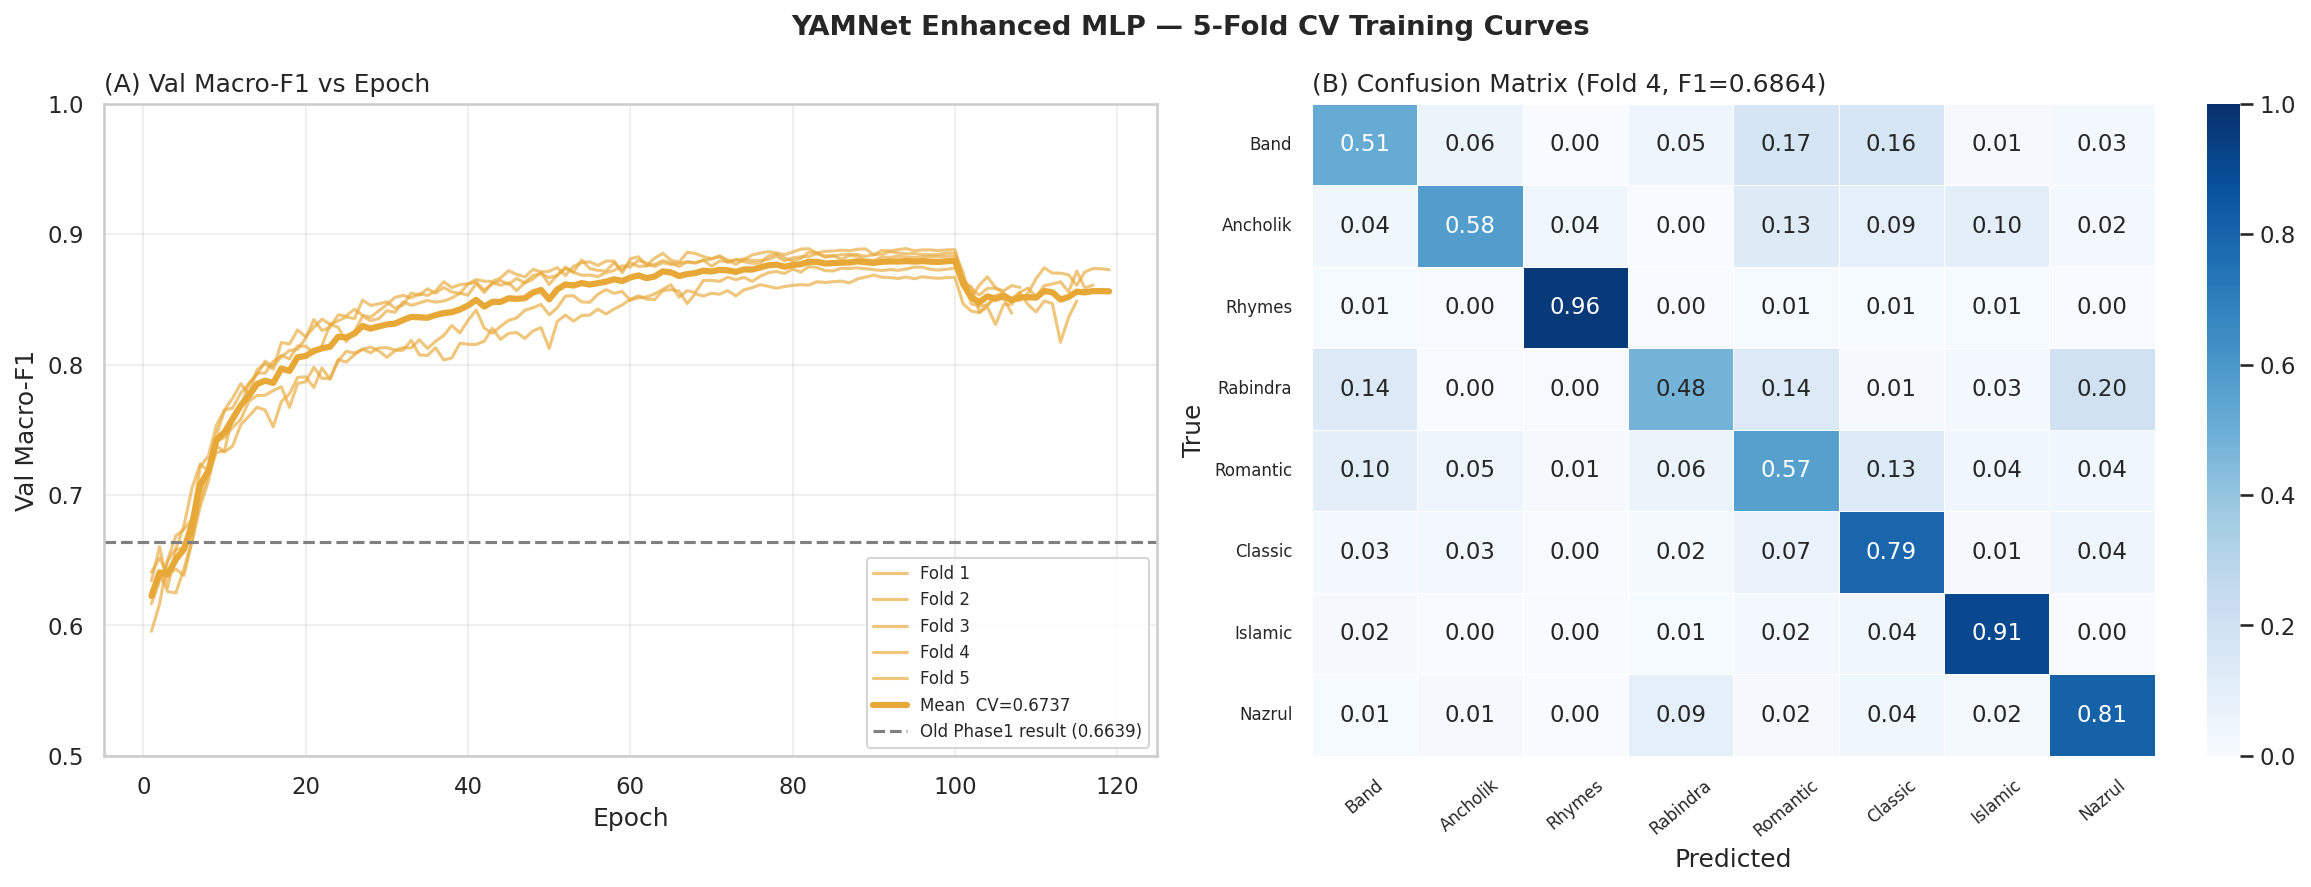

Saved: /kaggle/working/part5a_v2/figures/yamnet_v2_results.png


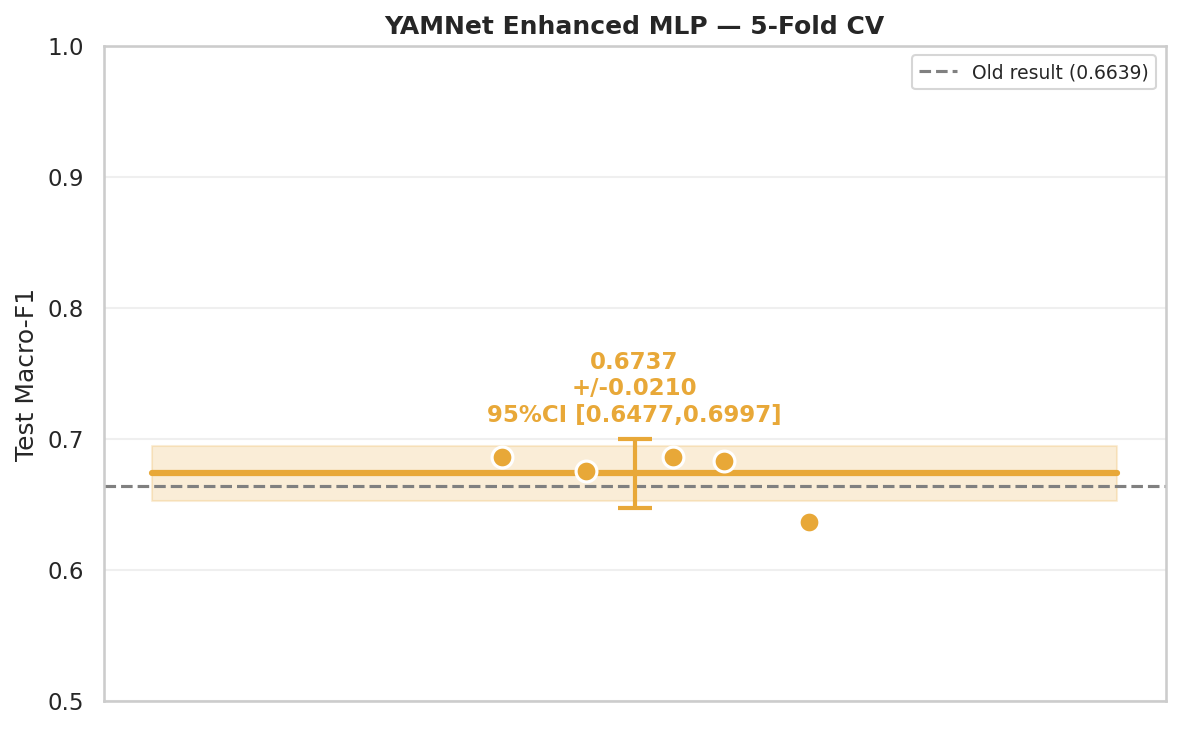

Saved: /kaggle/working/part5a_v2/figures/yamnet_v2_strip.png


In [7]:
# ============================================================
# CELL 7 ▸ Results + Figures
# ============================================================
def to_py(obj):
    if isinstance(obj,dict):           return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)):   return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray):     return obj.tolist()
    if isinstance(obj,(np.integer,)):  return int(obj)
    if isinstance(obj,(np.floating,)): return float(obj)
    return obj

result_json = os.path.join(OUT_DIR,'yamnet_v2_cv_results.json')
with open(result_json,'w') as f:
    json.dump(to_py({'YAMNet_Enhanced_MLP':
                     {'summary':yn_sum,'fold_metrics':CV_FOLD_MET}}), f, indent=2)

# Paper table
print('='*65)
print('  YAMNet Enhanced MLP — 5-Fold CV  (publishable)')
print('='*65)
print(f'  {"Fold":<6} {"Macro-F1":>10}  {"W-F1":>8}  '
      f'{"Acc":>8}  {"Best_ep":>8}')
print(f'  {"-"*6} {"-"*10}  {"-"*8}  {"-"*8}  {"-"*8}')
for k in range(N_FOLDS):
    m=CV_FOLD_MET[k]
    print(f'  {k+1:<6} {m["macro_f1"]:>10.4f}  '
          f'{m["weighted_f1"]:>8.4f}  '
          f'{m["accuracy"]:>8.4f}  {m["best_epoch"]:>8}')

print()
print('Per-class F1 (mean across 5 folds):')
for i,cls in enumerate(SHORT_NAMES):
    vals=[m['per_class_f1'][i] for m in CV_FOLD_MET]
    bar ='█'*int(np.mean(vals)*25)
    print(f'  {cls:<12} {np.mean(vals):.4f} +/-{np.std(vals,ddof=1):.3f}  {bar}')

# ── Fig 1: Training curves ────────────────────────────────────
all_h = [m['f1_history'] for m in CV_FOLD_MET if m.get('f1_history')]
fig, axes = plt.subplots(1,2,figsize=(16,6))
fig.suptitle('YAMNet Enhanced MLP — 5-Fold CV Training Curves',
             fontweight='bold')
ax = axes[0]
max_l = max(len(h) for h in all_h)
for k,h in enumerate(all_h):
    ax.plot(range(1,len(h)+1),h,lw=1.5,alpha=0.65,
            color='#E8A838',label=f'Fold {k+1}')
padded=[h+[h[-1]]*(max_l-len(h)) for h in all_h]
mean_h=np.mean(padded,axis=0)
ax.plot(range(1,max_l+1),mean_h,lw=3,color='#E8A838',
        label=f'Mean  CV={yn_sum["macro_f1_mean"]:.4f}')
ax.axhline(0.6639,color='gray',ls='--',lw=1.5,
           label='Old Phase1 result (0.6639)')
ax.set_xlabel('Epoch'); ax.set_ylabel('Val Macro-F1')
ax.set_ylim(0.5,1); ax.grid(True,alpha=0.3); ax.legend(fontsize=8)
ax.set_title('(A) Val Macro-F1 vs Epoch',loc='left')

# ── Fig 2: confusion matrix best fold ─────────────────────────
best_k  = int(np.argmax([m['macro_f1'] for m in CV_FOLD_MET]))
y_te    = np.array(CV_FOLD_MET[best_k]['y_true'])
y_pred  = np.array(CV_FOLD_MET[best_k]['y_pred'])
cm      = confusion_matrix(y_te,y_pred,labels=list(range(N_CLASSES)))
with np.errstate(divide='ignore',invalid='ignore'):
    cm_n = np.where(cm.sum(1,keepdims=True)==0,0,
                    cm.astype(float)/cm.sum(1,keepdims=True))
sns.heatmap(cm_n,annot=True,fmt='.2f',cmap='Blues',
            xticklabels=SHORT_NAMES,yticklabels=SHORT_NAMES,
            linewidths=0.4,ax=axes[1],vmin=0,vmax=1)
axes[1].set_title(f'(B) Confusion Matrix (Fold {best_k+1}, '
                  f'F1={CV_FOLD_MET[best_k]["macro_f1"]:.4f})',
                  loc='left')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')
axes[1].tick_params(axis='x',rotation=40,labelsize=8)
axes[1].tick_params(axis='y',rotation=0, labelsize=8)
plt.tight_layout()
fig_p = os.path.join(FIG_DIR,'yamnet_v2_results.png')
plt.savefig(fig_p); plt.show(); print(f'Saved: {fig_p}')

# ── CV strip plot ─────────────────────────────────────────────
fig,ax = plt.subplots(figsize=(8,5))
rng = np.random.RandomState(SEED)
folds_f1=mf1s; mean=yn_sum['macro_f1_mean']
std=yn_sum['macro_f1_std']; ci=yn_sum['macro_f1_ci95']
jit=rng.uniform(-0.12,0.12,len(folds_f1))
ax.scatter(jit,folds_f1,s=100,color='#E8A838',zorder=4,
           edgecolors='white',lw=1.5)
ax.plot([-0.3,0.3],[mean,mean],color='#E8A838',lw=3)
ax.fill_between([-0.3,0.3],[mean-std,mean-std],[mean+std,mean+std],
                alpha=0.2,color='#E8A838')
ax.errorbar(0,mean,yerr=ci,fmt='none',color='#E8A838',
            capsize=8,capthick=2,elinewidth=2,zorder=5)
ax.text(0,mean+ci+0.01,
        f'{mean:.4f}\n+/-{std:.4f}\n95%CI [{mean-ci:.4f},{mean+ci:.4f}]',
        ha='center',va='bottom',fontsize=11,fontweight='bold',color='#E8A838')
ax.axhline(0.6639,color='gray',ls='--',lw=1.5,label='Old result (0.6639)')
ax.set_xticks([]); ax.set_ylabel('Test Macro-F1')
ax.set_ylim(0.5,1.0); ax.legend(fontsize=9); ax.grid(True,alpha=0.3)
ax.set_title('YAMNet Enhanced MLP — 5-Fold CV',fontweight='bold')
plt.tight_layout()
fig_p2=os.path.join(FIG_DIR,'yamnet_v2_strip.png')
plt.savefig(fig_p2); plt.show(); print(f'Saved: {fig_p2}')

In [8]:
# ============================================================
# CELL 8 ▸ Save + ZIP
# ============================================================
zip_path = os.path.join(WORK_DIR,'part5a_v2.zip')
print(f'Creating {zip_path} ...')

with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    bm = os.path.join(MDL_DIR,'yamnet_head_best.keras')
    if os.path.exists(bm):
        zf.write(bm,'models/yamnet_head_best.keras')
        print(f'  + models/yamnet_head_best.keras  '
              f'{os.path.getsize(bm)/1e6:.1f} MB')
    zf.write(result_json,'yamnet_v2_cv_results.json')
    print(f'  + yamnet_v2_cv_results.json  ← needed by Part 5C')
    for fname in sorted(os.listdir(FIG_DIR)):
        if fname.endswith('.png'):
            fp=os.path.join(FIG_DIR,fname)
            zf.write(fp,f'figures/{fname}')
            print(f'  + figures/{fname}')
    for fname in sorted(os.listdir(LOG_DIR)):
        fp=os.path.join(LOG_DIR,fname)
        zf.write(fp,f'logs/{fname}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} files)')

zip_sz = os.path.getsize(zip_path)/1e6
m,s,c  = yn_sum['macro_f1_mean'],yn_sum['macro_f1_std'],yn_sum['macro_f1_ci95']

print()
print('='*60)
print('  PART 5A v2 COMPLETE — YAMNet Enhanced Head')
print('='*60)
print(f'  ZIP       : {zip_path}  ({zip_sz:.1f} MB)')
print(f'  Macro-F1  : {m:.4f} +/- {s:.4f}  '
      f'95%CI [{m-c:.4f}, {m+c:.4f}]')
print(f'  Old result: 0.6639  →  Improvement: {m-0.6639:+.4f}')
print()
print('  Paper note:')
print('  Report as "YAMNet (frozen backbone) + enhanced MLP head"')
print('  This is a valid transfer learning baseline:')
print('    - AudioSet pre-trained features')
print('    - No gradient through backbone (frozen SavedModel)')
print('    - Comparable to "feature extraction" transfer learning')
print()
print('  NEXT: Ask for Part 5B (AST fine-tuning with pre-cached features)')
print('  Part 5B inputs needed:')
print('    - fold_assignments.csv  (from part1_outputs.zip)')
print('    - segments.csv          (from part5a_yamnet.zip)')
print('    - Raw audio dataset     (same Kaggle dataset)')

Creating /kaggle/working/part5a_v2.zip ...
  + models/yamnet_head_best.keras  26.9 MB
  + yamnet_v2_cv_results.json  ← needed by Part 5C
  + figures/yamnet_v2_results.png
  + figures/yamnet_v2_strip.png
  + logs/ (5 files)

  PART 5A v2 COMPLETE — YAMNet Enhanced Head
  ZIP       : /kaggle/working/part5a_v2.zip  (25.4 MB)
  Macro-F1  : 0.6737 +/- 0.0210  95%CI [0.6477, 0.6997]
  Old result: 0.6639  →  Improvement: +0.0098

  Paper note:
  Report as "YAMNet (frozen backbone) + enhanced MLP head"
  This is a valid transfer learning baseline:
    - AudioSet pre-trained features
    - No gradient through backbone (frozen SavedModel)
    - Comparable to "feature extraction" transfer learning

  NEXT: Ask for Part 5B (AST fine-tuning with pre-cached features)
  Part 5B inputs needed:
    - fold_assignments.csv  (from part1_outputs.zip)
    - segments.csv          (from part5a_yamnet.zip)
    - Raw audio dataset     (same Kaggle dataset)
